<a href="https://colab.research.google.com/github/shengpu-tang/RL-Off-by-a-Beat/blob/main/Toy_Problem_Simulation_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
%config InlineBackend.figure_formats = ['svg']
from scipy.integrate import solve_ivp

## Continuous-Time Control Task

$\operatorname{sign}(y'(t)) = u(t)$

$y'(t) = \frac{1}{\tau}(u(t)-y(t))$

### Env & Policy
- BinaryExp1D
- HysteresisPolicy

In [ ]:
import numpy as np
from dataclasses import dataclass
from typing import Callable, Tuple, Dict, Any, Optional

@dataclass
class BinaryExp1D:
    """
    1D continuous state x in [0,1] with binary control u in {0,1}.
    Dynamics:
      if u=1: dx/dt = (1-x) / τ_1     -> increase, x(t+δ) = 1 - (1-x)*exp(-δ/τ_1)
      if u=0: dx/dt = (0-x) / τ_0     -> decrease, x(t+δ) = x*exp(-δ/τ_0)
    """
    dt: float = 1.0             # time elapsed per step()
    x: float = 0.0              # current state
    x_min: float = 0.0          # minimum state
    x_max: float = 1.0          # maximum state
    tau_1: float = 1.0          # rate of expoential increase when u=1
    tau_0: float = 1.0          # rate of expoential decrease when u=0
    clip_state: bool = True     # keep x in [x_min, x_max]

    def reset(self, x0: Optional[float] = None, rng: Optional[np.random.Generator] = None) -> float:
        if x0 is not None:
            self.x = float(x0)
        else:
            if rng is not None:
                self.x = float(rng.random())
            else:
                self.x = float(np.random.random())
        return self.x

    def _internal_step(self, x: float, u: int, δ: float) -> float:
        if u == 1:
            return 1.0 - (1.0 - x) * np.exp(-δ / self.tau_1)
        else:
            return x * np.exp(-δ / self.tau_0)

    def step(self, u: int, internal_dt: Optional[float] = None):
        """
        Evolves system for self.dt by numerical integration at internal_dt resolution.
        """
        step_dt = self.dt
        if internal_dt is None:
            internal_dt = step_dt # Use self.dt as default when internal_dt is None

        if internal_dt > step_dt:
            raise ValueError("internal_dt must be smaller than step_dt")
        else:
            n_sub = int(np.ceil(step_dt / internal_dt))
            internal_dt = step_dt / n_sub  # adjust to fit evenly

        x_traj = [self.x]
        t_traj = [0.0]

        x_curr = self.x
        for i in range(n_sub):
            x_next = self._internal_step(x_curr, u, internal_dt)
            if self.clip_state:
                x_next = float(np.clip(x_next, self.x_min, self.x_max))

            x_curr = x_next
            t_traj.append((i + 1) * internal_dt)
            x_traj.append(x_curr)

        # Reward is indicator of whether x has increased
        reward = float(int(x_curr >= self.x))
        self.x = x_curr

        done = False

        info = {"u": u}
        if internal_dt is not None:
            info["internal_t"] = np.array(t_traj)
            info["internal_x"] = np.array(x_traj)
            info["internal_u"] = np.array([u] * len(t_traj))

        return float(self.x), reward, done, info

In [ ]:
# a simple hysteresis policy (avoids chatter):
# turn ON if x < 0.4; turn OFF if x > 0.6; otherwise keep previous action
class HysteresisPolicy:
    def __init__(self, low=0.1, high=0.9, u0=1):
        self.low = low
        self.high = high
        self.u = u0
    def __call__(self, t, x):
        if x < self.low:
            self.u = 1
        elif x > self.high:
            self.u = 0
        return self.u

### Helper functions

- rollout_policy()
- stitch_internal_traj()

In [ ]:
def rollout_policy(
    env: BinaryExp1D,
    policy: Callable[[float, float], Any],
    T: float,
    x0: Optional[float] = None,
) -> Dict[str, np.ndarray]:
    """
    Evaluate an arbitrary policy pi(t, x) at discrete times t_k with ZOH over each step.
    - policy: function taking (t, x) and returning a control (we threshold to {0,1}).
    - T: total simulation horizon (seconds).
    - dt: override env.dt if provided (env is stepped with that dt).
    Returns dict with arrays: t, x, u, r
    """
    t = 0.0
    n_steps = int(np.ceil(T / env.dt))

    x_hist, u_hist, r_hist, t_hist, info_list = [], [], [], [], []

    x = env.reset(x0 if x0 is not None else env.x)

    for k in range(n_steps):
        u = policy(t, x)
        x, r, done, info = env.step(u, internal_dt=0.01)
        x_hist.append(x)
        u_hist.append(int(float(u) >= 0.5))
        r_hist.append(r)
        t_hist.append(t + env.dt)
        info_list.append(info)
        t += env.dt
        if done:
            break

    return {
        "t": np.array(t_hist, dtype=float),
        "x": np.array(x_hist, dtype=float),
        "u": np.array(u_hist, dtype=int),
        "r": np.array(r_hist, dtype=float),
        "info": info_list,
    }

In [ ]:
def stitch_internal_traj(info_list, step_dt):
    t_traj = []
    x_traj = []
    u_traj = []

    t0 = 0.0
    step = 0
    for info in info_list:
        it = np.asarray(info["internal_t"])
        ix = np.asarray(info["internal_x"])
        iu = np.asarray(info["internal_u"])
        u = int(info["u"])
        t_abs = t0 + it  # shift internal times to absolute
        if step < len(info_list) - 1:
            t_traj.append(t_abs[:-1])
            x_traj.append(ix[:-1])
            u_traj.append(iu[:-1])
            # u_traj.extend([u] * (len(t_abs)-1))
        else:
            t_traj.append(t_abs)
            x_traj.append(ix)
            u_traj.append(iu)
            # u_traj.extend([u] * len(t_abs))

        t0 += step_dt
        step += 1

    t_traj_ = [t_traj__[0] for t_traj__ in t_traj]
    u_traj_ = [info['u'] for info in info_list]

    t_traj = np.concatenate(t_traj)
    x_traj = np.concatenate(x_traj)
    u_traj = np.concatenate(u_traj)
    u_traj = np.array(u_traj, dtype=int)

    return {
        't_traj': t_traj,
        'x_traj': x_traj,
        'u_traj': u_traj,
        't_traj_': t_traj_,
        'u_traj_': u_traj_,
    }

### Plotting

In [ ]:
env = BinaryExp1D(tau_1=0.3, tau_0=0.3, dt=1.0)
pi = HysteresisPolicy(low=0.1, high=0.9, u0=1)
out = rollout_policy(env, pi, T=4.0, x0=0.1)

# quick check
print("Final state:", out["x"][-1])
print("Average control usage:", out["u"].mean())

stitched_traj = stitch_internal_traj(out["info"], step_dt=env.dt)
t_traj = stitched_traj['t_traj']
x_traj, u_traj = stitched_traj['x_traj'], stitched_traj['u_traj']
t_traj_, u_traj_ = stitched_traj['t_traj_'], stitched_traj['u_traj_']

Final state: 0.03444530183856196
Average control usage: 0.5


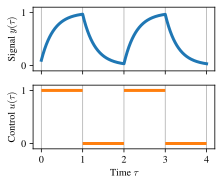

In [ ]:
# Plotting
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:orange'
axes[0].grid(axis='x')
axes[1].grid(axis='x')
axes[0].plot(t_traj, x_traj, lw=3, color=c1)
# axes[1].plot(t_traj, u_traj, lw=3, color=c2)
axes[1].hlines(u_traj_, t_traj_, t_traj_[1:] + [t_traj[-1]], lw=3, color=c2)
# axes[1].plot(t_traj_, u_traj_, lw=0, marker='s', color=c2)
axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
plt.tight_layout()
plt.savefig('toy_problem_NEW.pdf', bbox_inches='tight')
plt.xlabel('Time $\\tau$')
axes[0].set_ylabel('Signal $y(\\tau)$')
axes[1].set_ylabel('Control $u(\\tau)$')
plt.savefig('toy_problem_NEW_labeled.pdf', bbox_inches='tight')
plt.show()

## Simulation Setup

### Wrapped ToyEnv with imperfect control

In [ ]:
import numpy as np
from tqdm import tqdm

import gymnasium as gym
from gymnasium.envs.toy_text.utils import categorical_sample
from gymnasium.wrappers import TimeLimit

from collections import defaultdict
from typing import List, Optional

In [ ]:
nS, nA = 2, 2

class ToyEnvNew(gym.Env):
    """
    A wrapper around the continuous BinaryExp1D system with
    discrete-state (2 states: decreasing or increasing/steady) and
    discrete-action (2 actions: off and on).
    With slip_prob chance the requested action is ineffective and
    the previously applied control persists.
    """

    def __init__(self, **kwargs):
        super().__init__()

        self.slip_prob = kwargs.pop('slip_prob', 0.0)
        self.internal_dt = kwargs.pop('internal_dt', None)
        self.continuous_env = BinaryExp1D(**kwargs)

        self.nS = nS
        self.nA = nA
        self.observation_space = gym.spaces.Discrete(self.nS)  # 0: x decreasing, 1: x increasing/steady
        self.action_space = gym.spaces.Discrete(self.nA)       # 0: u=0 (Off), 1: u=1 (On)
        self.isd = np.ones(nS) / nS   # uniform initial state distribution

        # State variables
        self.s = None                  # signal increasing or decreasing
        self.a_last_requested = None   # action requested by agent in the last step
        self.u_last_effective = None   # control input that was actually applied to the system last step - this is contemperaneous with s

        print(f"ToyEnvNew initialized. step_dt={self.continuous_env.dt}, internal_dt={self.internal_dt}, slip_prob={self.slip_prob}")

    def _get_discrete_state(self, x_start: float, x_end: float) -> int:
        """
        Maps continuous state change (x_start -> x_end) to discrete state s in {0, 1}.
        0: x is decreasing (x_end < x_end)
        1: x is increasing (x_end > x_end) or steady
        """
        return 1 if x_end >= x_start else 0

    def step(self, a: int) -> Tuple[int, float, bool, bool, Dict]:
        """
        Execute action on the continuous system at internal_dt reslution.
        Returns the new state (based on direction of change) and internal trajectory of t and x.
        """
        if not self.action_space.contains(a):
            raise ValueError(f"Invalid action: {a}. Must be in {self.action_space}")

        x_start = self.continuous_env.x
        a_requested = a
        slipped = self.np_random.random() < self.slip_prob

        # Determine the action that actually influences the system (u_applied)
        # Use the last effective control if slipped, otherwise use the requested action
        u_applied = self.u_last_effective if slipped else a_requested

        # # Alternative version: slip to opposite action
        # u_applied = a_requested if not slipped else 1 - a_requested

        x_end, _, done, info = self.continuous_env.step(int(u_applied), internal_dt=self.internal_dt)
        s_next = self._get_discrete_state(x_start, x_end)

        # Update state variables
        self.s = s_next
        self.a_last_requested = a_requested
        self.u_last_effective = u_applied

        info["continuous_x_start"] = x_start
        info["continuous_x_end"] = x_end
        info["slip_status"] = "slip" if slipped else "success"
        info["a_last_requested"] = a_requested
        info["u_last_effective"] = u_applied

        # truncation=False, will be handled by the `TimeLimit` wrapper added during `make`
        return s_next, float(s_next), done, False, info

    def reset(self, seed: Optional[int] = None, options: Optional[Dict] = None) -> Tuple[int, Dict]:
        super().reset(seed=seed)

        # Create a specific RNG for the continuous environment's initial state if no x0 is given
        # This ensures the initial continuous state is deterministic based on the reset_seed,
        # irrespective of how super().reset() handles self.np_random's state for subsequent calls.
        initial_x_rng = np.random.default_rng(seed) if seed is not None else None

        x0 = options.get("x0") if options and "x0" in options else None
        self.continuous_env.reset(x0=x0, rng=initial_x_rng)

        if options and "s" in options:
            self.s = options["s"]
        else:
            # self.s = int(categorical_sample(self.isd, self.np_random))
            self.s = int(self.continuous_env.x > 0.5)

        self.a_last_requested = self.s    # assume last requested action is consistent with current state
        self.u_last_effective = self.s    # assume last applied action is consistent with current state

        info = {"continuous_x0": self.continuous_env.x}

        return self.s, info

In [ ]:
import numpy as np
import gymnasium as gym
from gymnasium.wrappers import TimeLimit
from typing import Tuple, Dict, Any, Optional

class ToyEnvDelayControl(ToyEnvNew):
    """
    A subclass of ToyEnvNew where the requested action's effect is delayed.
    The action requested at time k is applied in the continuous environment
    during the time step k+1.
    """

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # This will store the action requested by the agent in the *current*
        # discrete step, to be actually applied to the continuous environment
        # in the *next* discrete step.
        self._action_requested_for_next_step = None
        print(f"ToyEnvDelayControl initialized. step_dt={self.continuous_env.dt}, internal_dt={self.internal_dt}, slip_prob={self.slip_prob}")

    def reset(self, seed: Optional[int] = None, options: Optional[Dict] = None) -> Tuple[int, Dict]:
        s, info = super().reset(seed=seed, options=options)

        # For the very first `step(a)` call, there is no 'previous' agent request.
        # We need an initial action to apply to the continuous environment for that first step.
        # We'll use the initial discrete state `s` as a default for this initial delayed action.
        # This means the agent's first actual action `a` (passed to the first step() call)
        # will only take effect in the second discrete step.
        self._action_requested_for_next_step = self.s

        # The `a_last_requested` and `u_last_effective` attributes from the super().reset()
        # are now interpreted as the agent's implicit request and the effective control
        # for the state *before* any new action is taken in this delayed setup.
        return s, info

    def step(self, a: int) -> Tuple[int, float, bool, bool, Dict]:
        if not self.action_space.contains(a):
            raise ValueError(f"Invalid action: {a}. Must be in {self.action_space}")

        # 1. The agent's *current* request (parameter 'a') is stored for the *next* discrete step.
        current_agent_request = a

        # 2. The action that will be applied to the continuous environment *for this current discrete step*
        #    is the one that was requested by the agent in the *previous* discrete step.
        action_to_apply_to_continuous_env = self._action_requested_for_next_step

        x_start = self.continuous_env.x
        slipped = self.np_random.random() < self.slip_prob

        # Determine the final action actually fed to the continuous system,
        # incorporating the slip probability.
        # If slipped, the control remains `self.u_last_effective` (which is what was *actually applied* in the previous discrete step).
        # Otherwise, it's `action_to_apply_to_continuous_env` (which was *requested* by the agent in the previous discrete step).
        u_actually_applied_this_step = self.u_last_effective if slipped else action_to_apply_to_continuous_env

        # Take the continuous environment step with the determined control.
        x_end, _, done, info = self.continuous_env.step(int(u_actually_applied_this_step), internal_dt=self.internal_dt)
        s_next = self._get_discrete_state(x_start, x_end)

        # Update the discrete state of the environment.
        self.s = s_next

        # Update attributes for tracking and for the 'info' dictionary.
        # `self.a_last_requested` stores the action the agent *just requested* (for the current discrete step).
        self.a_last_requested = current_agent_request
        # `self.u_last_effective` stores the action that was *actually applied* to the continuous env in this step.
        self.u_last_effective = u_actually_applied_this_step

        # Crucially, update the action buffer for the *next* discrete step.
        self._action_requested_for_next_step = current_agent_request

        # Populate the info dictionary with details for this step.
        info["continuous_x_start"] = x_start
        info["continuous_x_end"] = x_end
        info["slip_status"] = "slip" if slipped else "success"
        info["a_last_requested"] = current_agent_request  # Agent's request for *this* discrete step
        info["u_last_effective"] = u_actually_applied_this_step # Action actually applied to continuous env *this* discrete step
        info["u"] = u_actually_applied_this_step # For consistency with original info dict, 'u' key is u_applied

        # Return the new discrete state, reward, termination status, truncation status, and info.
        return s_next, float(s_next), done, False, info

### Model-based RL functions

In [ ]:
def calculate_discounted_return(episode: List[Tuple[int, int, int, float, int]], gamma: float = 0.9) -> float:
    """
    Calculates the discounted return (G_0) for a single episode.
    G_t = R_{t+1} + gamma * R_{t+2} + gamma^2 * R_{t+3} + ...
    episode: list of (a_curr, s, a, r, s_next) tuples
    """
    rewards = [step[3] for step in episode]
    discounted_return = 0.0
    for t, reward in enumerate(rewards):
        discounted_return += (gamma ** t) * reward
    return discounted_return

In [ ]:
def calculate_reward_function(episodes):
    R_samples = defaultdict(list)
    for ep in episodes:
        for S, A, R, S_next in ep:
            R_samples[S, A].append(R)

    R = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            R[s,a] = np.mean(R_samples[s,a])

    return R

def calculate_transition_function(episodes):
    P = np.zeros((nS, nA, nS))
    for ep in episodes:
        for S, A, R, S_next in ep:
            P[S, A, S_next] += 1

    for s in range(nS):
        for a in range(nA):
            P[s, a, :] /= np.sum(P[s, a, :])

    return P

def value_iteration(P, R, gamma=0.9, theta=1e-10):
    # VI algorithm
    V = np.zeros(nS)
    while True:
        Q = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

        V_new = np.nanmax(Q, axis=1)
        delta = np.nanmax(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break

    # Calculate final Q-values
    Q = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

    # Final policy with tie-breaking
    π = (Q == np.nanmax(Q, axis=1, keepdims=True))
    π = π / π.sum(axis=1, keepdims=True)

    return V, Q, π

def policy_evaluation_iterative(P, R, π, gamma=0.9, theta=1e-10):
    V = np.zeros(nS)
    while True:
        Q = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

        V_new = np.nansum(π * Q, axis=1)
        delta = np.nanmax(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break

    # Calculate final Q-values
    Q = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

    return V, Q

def policy_evaluation(envP, π, gamma=0.9, theta=1e-10):
    V = np.zeros(nS)
    while True:
        delta = 0
        for s in range(nS):
            v = 0
            for a, a_prob in enumerate(π[s]):
                for prob, next_state, reward, done in envP[s][a]:
                    v += a_prob * prob * (reward + (1 - done) * gamma * V[next_state])

            delta = max(delta, np.abs(v - V[s]))
            V[s] = v
        if delta < theta:
            break
    return V

### One Run - debug version

In [ ]:
# Check deterministic initial state
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=1),
    max_episode_steps=10,
)

for _ in range(10):
    s, info = env.reset(seed=0)
    print(s)

ToyEnvNew initialized. step_dt=1.0, internal_dt=1, slip_prob=0.2
1
1
1
1
1
1
1
1
1
1


In [ ]:
# Check environment interface
env = TimeLimit(ToyEnvNew(slip_prob=0.2, internal_dt=0.01), max_episode_steps=100)

rng = np.random.default_rng(seed=0)
s, info = env.reset(seed=42)

episode_steps = []
for i in range(10):
    a_curr = int(env.env.a_last_requested)   # a_curr and s are contemporaneous
    a = int(categorical_sample(np.ones(nA)/nA, rng))
    s_next, r, terminated, truncated, info = env.step(a)
    episode_steps.append((a_curr, s, a, r, s_next))
    s = s_next
    if terminated or truncated:
        observation, info = env.reset()
        # print("Environment reset")

display(episode_steps)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.01, slip_prob=0.2


[(1, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 1, 0.0, 0),
 (1, 0, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1)]

In [ ]:
# Check environment interface
env = TimeLimit(ToyEnvDelayControl(slip_prob=0.2, internal_dt=0.01), max_episode_steps=100)

rng = np.random.default_rng(seed=0)
s, info = env.reset(seed=42)

episode_steps = []
for i in range(10):
    a_curr = int(env.env.a_last_requested)   # a_curr and s are contemporaneous
    a = int(categorical_sample(np.ones(nA)/nA, rng))
    s_next, r, terminated, truncated, info = env.step(a)
    episode_steps.append((a_curr, s, a, r, s_next))
    s = s_next
    if terminated or truncated:
        observation, info = env.reset()
        # print("Environment reset")

display(episode_steps)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.01, slip_prob=0.2
ToyEnvDelayControl initialized. step_dt=1.0, internal_dt=0.01, slip_prob=0.2


[(1, 1, 1, 1.0, 1),
 (1, 1, 0, 1.0, 1),
 (0, 1, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 1, 0.0, 0),
 (1, 0, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1)]

In [ ]:
# behavior policy
# prefer the action that would change the state
π_b = np.array([[0.1, 0.9], [0.75, 0.25]])

env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=1),
    max_episode_steps=10,
)

num_episodes = 100
episode_data = []
rng = np.random.default_rng(seed=42)

for ep in tqdm(range(num_episodes)):
    s, info = env.reset(seed=ep)
    episode_steps = []

    while True:
        a_curr = int(env.env.a_last_requested)
        a = rng.choice(nA, p=π_b[s])
        s_next, r, terminated, truncated, info = env.step(a)
        episode_steps.append((a_curr, s, a, r, s_next))
        s = s_next

        if terminated or truncated:
            break

    episode_data.append(episode_steps)

ToyEnvNew initialized. step_dt=1.0, internal_dt=1, slip_prob=0.2


100%|██████████| 100/100 [00:00<00:00, 304.28it/s]


In [ ]:
episode_data[0]

[(1, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 1, 0.0, 0),
 (1, 0, 1, 0.0, 0),
 (1, 0, 0, 0.0, 0),
 (0, 0, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 1, 1.0, 1)]

In [ ]:
episodes_orig = []
for ep in episode_data:
     episodes_orig.append([(s, a_curr, r, s_next) for a_curr, s, a, r, s_next in ep])

episodes_shifted = []
for ep in episode_data:
     episodes_shifted.append([(s, a, r, s_next) for a_curr, s, a, r, s_next in ep])

In [ ]:
episodes_orig[0]

[(1, 1, 1.0, 1),
 (1, 1, 0.0, 0),
 (0, 0, 0.0, 0),
 (0, 1, 0.0, 0),
 (0, 1, 0.0, 0),
 (0, 0, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 0.0, 0),
 (0, 0, 1.0, 1)]

In [ ]:
episodes_shifted[0]

[(1, 1, 1.0, 1),
 (1, 0, 0.0, 0),
 (0, 1, 0.0, 0),
 (0, 1, 0.0, 0),
 (0, 0, 0.0, 0),
 (0, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 0, 0.0, 0),
 (0, 1, 1.0, 1)]

In [ ]:
R_orig = calculate_reward_function(episodes_orig)
P_orig = calculate_transition_function(episodes_orig)
V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

In [ ]:
R_shifted = calculate_reward_function(episodes_shifted)
P_shifted = calculate_transition_function(episodes_shifted)
V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

In [ ]:
print(R_orig)
print(P_orig)
print(V_orig)
print(Q_orig)
print(π_orig)
print()
print(R_shifted)
print(P_shifted)
print(V_shifted)
print(Q_shifted)
print(π_shifted)

[[0.7287234  0.77922078]
 [0.42465753 0.38818565]]
[[[0.2712766  0.7287234 ]
  [0.22077922 0.77922078]]

 [[0.57534247 0.42465753]
  [0.61181435 0.38818565]]]
[5.90718438 5.638394  ]
[[5.86890289 5.90718438]
 [5.638394   5.61074508]]
[[0. 1.]
 [1. 0.]]

[[0.         0.79334917]
 [0.20192308 1.        ]]
[[[1.         0.        ]
  [0.20665083 0.79334917]]

 [[0.79807692 0.20192308]
  [0.         1.        ]]]
[ 9.74613364 10.        ]
[[ 8.77152028  9.74613364]
 [ 9.01957868 10.        ]]
[[0. 1.]
 [0. 1.]]


### Helper functions

- generate_random_behavior_policy()
- generate_near_optimal_behavior_policy()
- generate_dataset()
- run_experiment()
- run_experiment_evaluation()

In [ ]:
def generate_random_behavior_policy(n_states=2, n_actions=2, seed=None):
    policy = np.random.default_rng(seed=seed).random((n_states, n_actions))
    for state in range(n_states):
        policy[state] = policy[state] / np.sum(policy[state])
    return policy

def generate_near_optimal_behavior_policy(n_states=2, n_actions=2, seed=None):
    policy = np.zeros((n_states, n_actions))
    policy[:,0] = np.random.default_rng(seed=seed).random((1, n_actions))*0.05
    policy[:,1] = 1 - policy[:,0]
    return policy

def generate_per_state_near_optimal_behavior_policy(n_states=2, n_actions=2, seed=None):
    policy = np.zeros((n_states, n_actions))
    policy[0,0] = np.random.default_rng(seed=seed).random((1, n_actions))*0.05
    policy[0,1] = 1 - policy[0,0]
    policy[1,0] = np.random.default_rng(seed=seed).random((1, n_actions))*0.05
    policy[1,1] = 1 - policy[1,0]
    return policy

def generate_dataset(env, π_b, num_episodes=1, seed=None, show_progress=True):
    episode_data = []
    rng = np.random.default_rng(seed=seed)

    for ep in tqdm(range(num_episodes), disable=(not show_progress)):
        s, info = env.reset(seed=seed*1000+ep)
        episode_steps = []

        while True:
            a_curr = env.env.a_last_requested
            a = rng.choice(nA, p=π_b[s])
            s_next, r, terminated, truncated, info = env.step(a)
            episode_steps.append((a_curr, s, a, r, s_next, info))
            s = s_next

            if terminated or truncated:
                break

        episode_data.append(episode_steps)
    return episode_data

def run_experiment(episode_data):
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]

    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function(episodes_orig)
    V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function(episodes_shifted)
    V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

    return {
        'orig': {
            'R': R_orig, 'P': P_orig, 'V': V_orig, 'Q': Q_orig, 'π': π_orig,
        },
        'shifted': {
            'R': R_shifted, 'P': P_shifted, 'V': V_shifted, 'Q': Q_shifted, 'π': π_shifted,
        }
    }

def run_experiment_evaluation(outputs, episode_data, π_b):
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]

    π_orig = outputs['orig']['π']
    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function(episodes_orig)
    V_eval_orig, Q_eval_orig = policy_evaluation_iterative(P_orig, R_orig, π_orig)
    V_πb_orig, Q_πb_orig = policy_evaluation_iterative(P_orig, R_orig, π_b)

    π_shifted = outputs['shifted']['π']
    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function(episodes_shifted)
    V_eval_shifted, Q_eval_shifted = policy_evaluation_iterative(P_shifted, R_shifted, π_shifted)
    V_πb_shifted, Q_πb_shifted = policy_evaluation_iterative(P_shifted, R_shifted, π_b)

    return {
        'orig': {
            'V': V_eval_orig, 'Q': Q_eval_orig,
            'V_πb': V_πb_orig, 'Q_πb': Q_πb_orig,
        },
        'shifted': {
            'V': V_eval_shifted, 'Q': Q_eval_shifted,
            'V_πb': V_πb_shifted, 'Q_πb': Q_πb_shifted,
        }
    }

### One Run - with helper functions

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.1),
    max_episode_steps=100,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1


In [ ]:
π_b = np.array([[0.05, 0.95], [0.05, 0.95]])
episode_data = generate_dataset(env, π_b, seed=0, num_episodes=100, show_progress=False)
results = run_experiment(episode_data)

In [ ]:
results['orig']['π'], results['shifted']['π']

(array([[0., 1.],
        [1., 0.]]),
 array([[0., 1.],
        [0., 1.]]))

In [ ]:
test_episode_data = generate_dataset(env, π_b, seed=100, num_episodes=100, show_progress=False)
test_results = run_experiment_evaluation(results, test_episode_data, π_b)

In [ ]:
print(test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean())
print(test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean())

9.511421188452832 9.537088164098423
9.459140433498622 9.950289974287257


In [ ]:
online_rollout_orig = generate_dataset(env, results['orig']['π'], seed=100, num_episodes=100, show_progress=False)
online_rollout_shifted = generate_dataset(env, results['shifted']['π'], seed=100, num_episodes=100, show_progress=False)
returns_orig = [calculate_discounted_return(ep) for ep in online_rollout_orig]
returns_shifted = [calculate_discounted_return(ep) for ep in online_rollout_shifted]

In [ ]:
print(np.mean(returns_orig), np.mean(returns_shifted))

4.970532328873201 9.889734386011124


In [ ]:
π_b = generate_random_behavior_policy(2, 2, seed=3)
episode_data = generate_dataset(env, π_b, seed=42, show_progress=False)
results = run_experiment(episode_data)

In [ ]:
results['orig']['π'], results['shifted']['π']

(array([[1., 0.],
        [1., 0.]]),
 array([[0., 1.],
        [0., 1.]]))

In [ ]:
test_episode_data = generate_dataset(env, π_b, seed=100, show_progress=False)
test_results = run_experiment_evaluation(results, test_episode_data, π_b)

In [ ]:
test_results['orig']['V'], test_results['shifted']['V']

(array([6.39470783, 6.14112459]), array([ 9.87261146, 10.        ]))

In [ ]:
online_rollout_orig = generate_dataset(env, results['orig']['π'], seed=100, num_episodes=100, show_progress=False)
online_rollout_shifted = generate_dataset(env, results['shifted']['π'], seed=100, num_episodes=100, show_progress=False)
returns_orig = [calculate_discounted_return(ep) for ep in online_rollout_orig]
returns_shifted = [calculate_discounted_return(ep) for ep in online_rollout_shifted]

In [ ]:
print(np.mean(returns_orig), np.mean(returns_shifted))

0.0 9.889734386011124


## Main Experiments - random behavior policy

### Learning

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2


In [ ]:
all_results = []
for run in tqdm(range(100)):
    π_b = generate_random_behavior_policy(2, 2, seed=run)
    episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=100+run, show_progress=False)
    results = run_experiment(episode_data)
    all_results.append(results)

 25%|██▌       | 25/100 [00:16<00:45,  1.63it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipython-input-1230074664.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
100%|██████████| 100/100 [01:05<00:00,  1.52it/s]


In [ ]:
# average P
avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)

In [ ]:
avg_P_orig, avg_P_shifted

(array([[[0.61141575, 0.38858425],
         [0.60452609, 0.39547391]],
 
        [[0.39898976, 0.60101024],
         [0.39995943, 0.60004057]]]),
 array([[[1.        , 0.        ],
         [0.20001372, 0.79998628]],
 
        [[0.80382701, 0.19617299],
         [0.        , 1.        ]]]))

In [ ]:
# average R
avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)

In [ ]:
avg_R_orig, avg_R_shifted

(array([[0.38858425, 0.39547391],
        [0.60101024, 0.60004057]]),
 array([[0.        , 0.79998628],
        [0.19617299, 1.        ]]))

In [ ]:
# average V
avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)

# average Q
avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)

In [ ]:
# average π
avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)

In [ ]:
avg_π_orig, avg_π_shifted

(array([[0.5 , 0.5 ],
        [0.55, 0.45]]),
 array([[0., 1.],
        [0., 1.]]))

### Result Figures

In [ ]:
sa = [(0,0), (0,1), (1,0), (1,1)]
s_ = [0, 1]

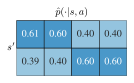

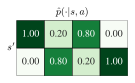

In [ ]:
df_Phat_orig = pd.DataFrame(avg_P_orig.reshape((4,2)), index=sa, columns=s_)

fig, ax = plt.subplots(figsize=(2, 1))
sns.heatmap(
    df_Phat_orig.T, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{p}(\cdot | s,a)$')
plt.ylabel("$s'$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.05, 0.425)
plt.savefig('synthetic_p_hat_orig.pdf', bbox_inches='tight')
plt.show()

df_Phat_shifted = pd.DataFrame(avg_P_shifted.reshape((4,2)), index=sa, columns=s_)

fig, ax = plt.subplots(figsize=(2, 3.5))
sns.heatmap(
    df_Phat_shifted.T, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{p}(\cdot | s,a)$')
plt.ylabel("$s'$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.05, 0.425)
plt.savefig('synthetic_p_hat_shifted.pdf', bbox_inches='tight')
plt.show()

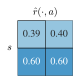

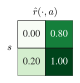

In [ ]:
df_Rhat_orig = pd.DataFrame(avg_R_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Rhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{r}(\cdot,a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_r_hat_orig.pdf', bbox_inches='tight')
plt.show()

df_Rhat_shifted = pd.DataFrame(avg_R_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Rhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{r}(\cdot,a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_r_hat_shifted.pdf', bbox_inches='tight')
plt.show()

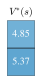

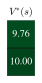

In [ ]:
df_Vhat_orig = pd.DataFrame(avg_V_orig, index=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Vhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel('$V^{*}(s)$')
ax.xaxis.set_label_coords(0.5, 1.24)
plt.savefig('synthetic_Vstar_orig.pdf', bbox_inches='tight')
plt.show()

df_Vhat_shifted = pd.DataFrame(avg_V_shifted, index=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Vhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel('$V^{*}(s)$')
ax.xaxis.set_label_coords(0.5, 1.24)
plt.savefig('synthetic_Vstar_shifted.pdf', bbox_inches='tight')
plt.show()

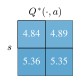

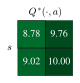

In [ ]:
df_Qhat_orig = pd.DataFrame(avg_Q_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Qhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$Q^{*}(\cdot, a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_Qstar_orig.pdf', bbox_inches='tight')
plt.show()

df_Qhat_shifted = pd.DataFrame(avg_Q_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Qhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$Q^{*}(\cdot, a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_Qstar_shifted.pdf', bbox_inches='tight')
plt.show()

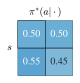

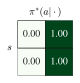

In [ ]:
df_πhat_orig = pd.DataFrame(avg_π_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_πhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\pi^{*}(a | \cdot)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_pistar_orig.pdf', bbox_inches='tight')
plt.show()

df_πhat_shifted = pd.DataFrame(avg_π_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_πhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\pi^{*}(a | \cdot)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_pistar_shifted.pdf', bbox_inches='tight')
plt.show()

### Offline evaluation

In [ ]:
all_test_results = []
for run in tqdm(range(100)):
    π_b = generate_random_behavior_policy(2, 2, seed=run)
    test_episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=200+run, show_progress=False)
    test_results = run_experiment_evaluation(all_results[run], test_episode_data, π_b)
    all_test_results.append(test_results)

100%|██████████| 100/100 [01:20<00:00,  1.24it/s]


In [ ]:
df_output = []
for test_results in all_test_results:
    df_output.append([
        test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean(),
        test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean(),
    ])

df_output = pd.DataFrame(df_output, columns=['V_πb_orig', 'V_orig', 'V_πb_shifted', 'V_shifted'])

In [ ]:
df_output['correct_π_orig'] = [np.all(results['orig']['π'] == results['shifted']['π']) for results in all_results]

In [ ]:
df_output

,V_πb_orig,V_orig,V_πb_shifted,V_shifted,correct_π_orig
0,2.933256,2.864575,3.029618,9.888668,True
1,8.062733,8.015409,8.085665,9.870898,True
2,3.751005,3.764736,3.676050,9.861903,False
3,5.630116,5.663622,5.580236,9.882493,False
4,2.658707,2.686193,2.713336,9.870527,False
...,...,...,...,...,...
95,6.191913,6.243160,6.206075,9.873674,True
96,4.963766,4.720532,4.826854,9.873562,True
97,5.258614,5.329825,5.237460,9.871484,False
98,6.878084,6.891207,6.857634,9.875164,False


In [ ]:
(~df_output['correct_π_orig']).mean()

np.float64(0.79)

In [ ]:
(df_output['V_πb_orig'] < df_output['V_orig']).mean()

np.float64(0.49)

In [ ]:
((df_output['V_πb_orig'] < df_output['V_orig']) & (~df_output['correct_π_orig'])).mean()

np.float64(0.4)

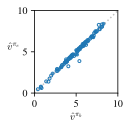

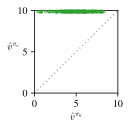

In [ ]:
Vmin, Vmax = 0, 10
fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[df_output['correct_π_orig']], markersize=3, alpha=0.75, color='tab:blue', zorder=10, clip_on=False)
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[~df_output['correct_π_orig']], markersize=3, mfc='none', alpha=1, color='tab:blue', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_stochastic_OPE_orig.pdf', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_shifted', 'V_shifted', 'o', data=df_output, markersize=3, alpha=0.5, color='tab:green', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_stochastic_OPE_shifted.pdf', bbox_inches='tight')
plt.show()

### Online evaluation

In [ ]:
P = np.array([
    [[1., 0.], [0.2, 0.8]],
    [[0.8, 0.2], [0., 1.]],
])
R = np.array([
    [0., 1.],
    [0., 1.],
])

In [ ]:
V_true_orig, _ = policy_evaluation_iterative(P, R, avg_π_orig)
V_true_shifted, _ = policy_evaluation_iterative(P, R, avg_π_shifted)

In [ ]:
print(V_true_orig.mean(), V_true_shifted.mean())

4.760514017837638 9.999999999142268


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
returns_orig = np.array([calculate_discounted_return(ep) for ep in online_rollout_orig])
returns_shifted = np.array([calculate_discounted_return(ep) for ep in online_rollout_shifted])

In [ ]:
print(returns_orig.mean(), returns_shifted.mean())

4.565134159356614 9.723634386011124


### Visualize online rollouts

In [ ]:
MAX_EPISODES_STEPS = 20
NUM_EPISODES = 500

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=0.05),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.05, slip_prob=0.2


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)

In [ ]:
orig_trajectories = []
for ep in online_rollout_orig:
    orig_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    orig_trajectories.append(orig_internal_traj)

shifted_trajectories = []
for ep in online_rollout_shifted:
    shifted_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    shifted_trajectories.append(shifted_internal_traj)

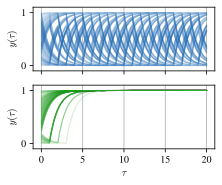

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:green'
axes[0].grid(axis='x')
axes[1].grid(axis='x')

for i in range(NUM_EPISODES):
    t_traj = orig_trajectories[i]['t_traj']
    x_traj = orig_trajectories[i]['x_traj']
    u_traj = orig_trajectories[i]['u_traj']
    t_traj_ = orig_trajectories[i]['t_traj_']
    u_traj_ = orig_trajectories[i]['u_traj_']
    axes[0].plot(t_traj, x_traj, lw=1, color=c1, alpha=0.2*100/NUM_EPISODES)

for i in range(NUM_EPISODES):
    t_traj = shifted_trajectories[i]['t_traj']
    x_traj = shifted_trajectories[i]['x_traj']
    u_traj = shifted_trajectories[i]['u_traj']
    t_traj_ = shifted_trajectories[i]['t_traj_']
    u_traj_ = shifted_trajectories[i]['u_traj_']
    axes[1].plot(t_traj, x_traj, lw=1, color=c2, alpha=0.2*100/NUM_EPISODES)

axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
# axes[0].set_title('"shifted"')
plt.tight_layout()
plt.xlabel('$\\tau$')
axes[0].set_ylabel('$y(\\tau)$')
axes[1].set_ylabel('$y(\\tau)$')
plt.savefig('toy_problem_online_rollout.pdf', bbox_inches='tight')
plt.show()

## Experiments with near-optimal behavior

### Learning

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.1),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1


In [ ]:
all_results = []
for run in tqdm(range(100)):
    π_b = generate_near_optimal_behavior_policy(2, 2, seed=run)
    episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=100+run, show_progress=False)
    results = run_experiment(episode_data)
    all_results.append(results)

  3%|▎         | 3/100 [00:02<01:03,  1.53it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipython-input-1230074664.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
100%|██████████| 100/100 [01:13<00:00,  1.36it/s]


In [ ]:
# average P
avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)

In [ ]:
avg_P_orig, avg_P_shifted

(array([[[0.12450969, 0.87549031],
         [0.1188107 , 0.8811893 ]],
 
        [[0.02524042, 0.97475958],
         [0.02400916, 0.97599084]]]),
 array([[[1.        , 0.        ],
         [0.09945518, 0.90054482]],
 
        [[0.90102527, 0.09897473],
         [0.        , 1.        ]]]))

In [ ]:
# average R
avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)

In [ ]:
avg_R_orig, avg_R_shifted

(array([[0.87549031, 0.8811893 ],
        [0.97475958, 0.97599084]]),
 array([[0.        , 0.90054482],
        [0.09897473, 1.        ]]))

In [ ]:
# average V
avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)

# average Q
avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)

In [ ]:
# average π
avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)

In [ ]:
avg_π_orig, avg_π_shifted

(array([[0.37, 0.63],
        [0.61, 0.39]]),
 array([[0., 1.],
        [0., 1.]]))

### Offline evaluation

In [ ]:
all_test_results = []
for run in tqdm(range(100)):
    π_b = generate_near_optimal_behavior_policy(2, 2, seed=run)
    test_episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=200+run, show_progress=False)
    test_results = run_experiment_evaluation(all_results[run], test_episode_data, π_b)
    all_test_results.append(test_results)

  3%|▎         | 3/100 [00:02<01:04,  1.50it/s]/tmp/ipython-input-1230074664.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
100%|██████████| 100/100 [01:07<00:00,  1.47it/s]


In [ ]:
df_output = []
for test_results in all_test_results:
    df_output.append([
        test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean(),
        test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean(),
    ])

df_output = pd.DataFrame(df_output, columns=['V_πb_orig', 'V_orig', 'V_πb_shifted', 'V_shifted'])

In [ ]:
df_output['correct_π_orig'] = [np.all(results['orig']['π'] == results['shifted']['π']) for results in all_results]

In [ ]:
df_output

,V_πb_orig,V_orig,V_πb_shifted,V_shifted,correct_π_orig
0,9.794140,9.911374,9.783689,9.934211,False
1,9.528414,9.509390,9.493912,9.943533,True
2,9.853919,9.337900,9.805312,9.947230,False
3,9.792537,9.896907,9.782713,9.919679,False
4,9.603458,9.863813,9.665728,9.942071,False
...,...,...,...,...,...
95,9.593774,9.406332,9.537693,9.949495,False
96,9.613794,9.611350,9.574101,9.932546,True
97,9.721300,9.385965,9.720639,9.946577,False
98,9.606288,9.586091,9.555216,9.962244,False


In [ ]:
(~df_output['correct_π_orig']).mean()

np.float64(0.75)

In [ ]:
(df_output['V_πb_orig'] < df_output['V_orig']).mean()

np.float64(0.49)

In [ ]:
((df_output['V_πb_orig'] < df_output['V_orig']) & (~df_output['correct_π_orig'])).mean()

np.float64(0.42)

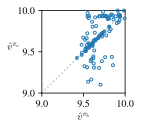

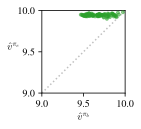

In [ ]:
Vmin, Vmax = 9, 10
fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[df_output['correct_π_orig']], markersize=3, alpha=0.75, color='tab:blue', zorder=10, clip_on=False)
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[~df_output['correct_π_orig']], markersize=3, mfc='none', alpha=1, color='tab:blue', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_near_deterministic_OPE_orig.pdf', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_shifted', 'V_shifted', 'o', data=df_output, markersize=3, alpha=0.5, color='tab:green', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_near_deterministic_OPE_shifted.pdf', bbox_inches='tight')
plt.show()

### Online evaluation

In [ ]:
P = np.array([
    [[1., 0.], [0.2, 0.8]],
    [[0.8, 0.2], [0., 1.]],
])
R = np.array([
    [0., 1.],
    [0., 1.],
])

In [ ]:
V_true_orig, _ = policy_evaluation_iterative(P, R, avg_π_orig)
V_true_shifted, _ = policy_evaluation_iterative(P, R, avg_π_shifted)

In [ ]:
print(V_true_orig.mean(), V_true_shifted.mean())

5.082594680888299 9.999999999142268


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
returns_orig = np.array([calculate_discounted_return(ep) for ep in online_rollout_orig])
returns_shifted = np.array([calculate_discounted_return(ep) for ep in online_rollout_shifted])

In [ ]:
print(returns_orig.mean(), returns_shifted.mean())

5.084023840450242 9.959734386011124


### Visualize online rollouts

In [ ]:
MAX_EPISODES_STEPS = 20
NUM_EPISODES = 500

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=0.05),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.05, slip_prob=0.2


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=300, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=300, num_episodes=NUM_EPISODES, show_progress=False)

In [ ]:
orig_trajectories = []
for ep in online_rollout_orig:
    orig_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    orig_trajectories.append(orig_internal_traj)

shifted_trajectories = []
for ep in online_rollout_shifted:
    shifted_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    shifted_trajectories.append(shifted_internal_traj)

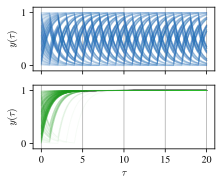

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:green'
axes[0].grid(axis='x')
axes[1].grid(axis='x')

for i in range(NUM_EPISODES):
    t_traj = orig_trajectories[i]['t_traj']
    x_traj = orig_trajectories[i]['x_traj']
    u_traj = orig_trajectories[i]['u_traj']
    t_traj_ = orig_trajectories[i]['t_traj_']
    u_traj_ = orig_trajectories[i]['u_traj_']
    axes[0].plot(t_traj, x_traj, lw=1, color=c1, alpha=0.2*100/NUM_EPISODES)

for i in range(NUM_EPISODES):
    t_traj = shifted_trajectories[i]['t_traj']
    x_traj = shifted_trajectories[i]['x_traj']
    u_traj = shifted_trajectories[i]['u_traj']
    t_traj_ = shifted_trajectories[i]['t_traj_']
    u_traj_ = shifted_trajectories[i]['u_traj_']
    axes[1].plot(t_traj, x_traj, lw=1, color=c2, alpha=0.2*100/NUM_EPISODES)

axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
# axes[0].set_title('"shifted"')
plt.tight_layout()
plt.xlabel('$\\tau$')
axes[0].set_ylabel('$y(\\tau)$')
axes[1].set_ylabel('$y(\\tau)$')
plt.savefig('toy_problem_near_deterministic_online_rollout.pdf', bbox_inches='tight')
plt.show()

## Change Temporal Granularities
- calculate_transition_function_alt()
- run_experiment_alt()
- stitch_internal_traj_NEW()
- resample_episode()

In [ ]:
def calculate_transition_function_alt(episodes):
    # allow generalization over states
    # such that transition depend only on action but not state
    P = np.zeros((nS, nA, nS))
    for ep in episodes:
        for S, A, R, S_next in ep:
            P[:, A, S_next] += 1  # <- accumulate counts irrespective of S

    for s in range(nS):
        for a in range(nA):
            P[s, a, :] /= np.sum(P[s, a, :])

    return P

def run_experiment_alt(episode_data):
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]

    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function_alt(episodes_orig)
    V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function_alt(episodes_shifted)
    V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

    return {
        'orig': {
            'R': R_orig, 'P': P_orig, 'V': V_orig, 'Q': Q_orig, 'π': π_orig,
        },
        'shifted': {
            'R': R_shifted, 'P': P_shifted, 'V': V_shifted, 'Q': Q_shifted, 'π': π_shifted,
        }
    }


In [ ]:
def stitch_internal_traj_NEW(info_list, step_dt):
    # Keeps the requested action so that episode steps can be resampled
    t_traj = []
    x_traj = []
    u_traj = []  # effective control
    a_traj = []  # requested control

    t0 = 0.0
    step = 0
    for info in info_list:
        it = np.asarray(info["internal_t"])
        ix = np.asarray(info["internal_x"])
        iu = np.asarray(info["internal_u"])
        a = int(info["a_last_requested"]) # Get requested action
        t_abs = t0 + it  # shift internal times to absolute
        if step < len(info_list) - 1:
            t_traj.append(t_abs[:-1])
            x_traj.append(ix[:-1])
            u_traj.append(iu[:-1])
            a_traj.append([a] * (len(t_abs)-1))
        else:
            t_traj.append(t_abs)
            x_traj.append(ix)
            u_traj.append(iu)
            a_traj.append([a] * len(t_abs))

        t0 += step_dt
        step += 1

    t_traj_ = [t_traj__[0] for t_traj__ in t_traj]
    u_traj_ = [info['u'] for info in info_list]
    a_traj_ = [info['a_last_requested'] for info in info_list] # Requested action per step

    t_traj = np.concatenate(t_traj)
    x_traj = np.concatenate(x_traj)
    u_traj = np.concatenate(u_traj)
    u_traj = np.array(u_traj, dtype=int)
    a_traj = np.concatenate(a_traj)
    a_traj = np.array(a_traj, dtype=int)

    return {
        't_traj': t_traj,
        'x_traj': x_traj,
        'u_traj': u_traj,
        'a_traj': a_traj,
        't_traj_': t_traj_,
        'u_traj_': u_traj_,
        'a_traj_': a_traj_,
    }

In [ ]:
def resample_episode(stitched_data_dict, new_step_dt, original_internal_dt):
    t_full_traj = stitched_data_dict['t_traj']
    x_full_traj = stitched_data_dict['x_traj']
    u_full_traj = stitched_data_dict['u_traj'] # effective control
    a_full_traj = stitched_data_dict['a_traj'] # requested control

    episode_steps = []

    # Calculate the number of new steps
    total_duration = t_full_traj[-1] if len(t_full_traj) > 0 else 0.0
    num_new_steps = int(np.ceil(total_duration / new_step_dt))

    # --- Initialization mimicking ToyEnvNew.reset() ---
    # Initial continuous state
    initial_x = x_full_traj[0] if len(x_full_traj) > 0 else 0.0
    # Initial discrete state s, using _get_discrete_state logic based on env.reset's behavior
    # ToyEnvNew.reset does `self.s = int(self.continuous_env.x > 0.5)`
    s_current_state = 1 if initial_x > 0.5 else 0

    # Initialize a_last_requested and u_last_effective as per ToyEnvNew.reset()
    # `self.a_last_requested = self.s`
    # `self.u_last_effective = self.s`
    # So for the *first* step's (a_curr, s, a, r, s_next), the `a_curr` will be `s_current_state`.
    a_curr_for_current_step = s_current_state

    for i in range(num_new_steps):
        t_start_new_step = i * new_step_dt
        t_end_new_step = (i + 1) * new_step_dt

        # Find indices in the full trajectory
        idx_start_full_traj = int(t_start_new_step / original_internal_dt)
        if idx_start_full_traj >= len(t_full_traj):
            break

        x_start_new_step = x_full_traj[idx_start_full_traj]

        idx_end_full_traj = int(t_end_new_step / original_internal_dt)
        if idx_end_full_traj >= len(t_full_traj):
            idx_end_full_traj = len(t_full_traj) - 1

        x_end_new_step = x_full_traj[idx_end_full_traj]

        # Determine s_next and reward
        s_next_new_step = 1 if x_end_new_step >= x_start_new_step else 0
        r_new_step = float(s_next_new_step)

        # Requested and effective actions for this resampled step interval
        a_requested_for_current_interval = a_full_traj[idx_start_full_traj]
        u_applied_for_current_interval = u_full_traj[idx_start_full_traj]

        # Construct info dictionary
        info_new_step = {
            'internal_t': t_full_traj[idx_start_full_traj : idx_end_full_traj + 1] - t_start_new_step,
            'internal_x': x_full_traj[idx_start_full_traj : idx_end_full_traj + 1],
            'internal_u': u_full_traj[idx_start_full_traj : idx_end_full_traj + 1],
            'continuous_x_start': x_start_new_step,
            'continuous_x_end': x_end_new_step,
            'slip_status': "slip" if a_requested_for_current_interval != u_applied_for_current_interval else "success",
            'a_last_requested': a_requested_for_current_interval, # This is the action requested *for the current interval*
            'u_last_effective': u_applied_for_current_interval,   # This is the action effectively applied *for the current interval*
            'u': u_applied_for_current_interval # 'u' field in info for ToyEnvNew
        }

        # Append the step
        # (a_curr, s, a, r, s_next, info)
        # a_curr is the requested action that led to the state `s_current_state`
        episode_steps.append((a_curr_for_current_step, s_current_state, a_requested_for_current_interval, r_new_step, s_next_new_step, info_new_step))

        # Update for the next iteration
        s_current_state = s_next_new_step
        a_curr_for_current_step = a_requested_for_current_interval # The requested action of *this* step becomes a_curr for the *next* step.

    return episode_steps

### Test resampling

In [ ]:
step_dt_old = 1
step_dt_new = 0.2
INTERNAL_DT = 0.05

In [ ]:
# behavior policy
# prefer the action that would change the state
π_b = np.array([[0.1, 0.9], [0.75, 0.25]])


# π_b = np.array([[0.5, 0.5], [0.5, 0.5]])

env = TimeLimit(
    ToyEnvNew(slip_prob=0.5, internal_dt=INTERNAL_DT, dt=step_dt_old),
    max_episode_steps=30,
)

ToyEnvNew initialized. step_dt=1, internal_dt=0.05, slip_prob=0.5


In [ ]:
episode_data = generate_dataset(env, π_b, num_episodes=1, seed=0, show_progress=True)

100%|██████████| 1/1 [00:00<00:00, 79.71it/s]


In [ ]:
stitched_episode = stitch_internal_traj_NEW([info for a_curr, s, a, r, s_next, info in episode_data[0]], step_dt_old)
tmp_t = stitched_episode['t_traj']
tmp_x = stitched_episode['x_traj']
tmp_u = stitched_episode['u_traj']
tmp_a = stitched_episode['a_traj']

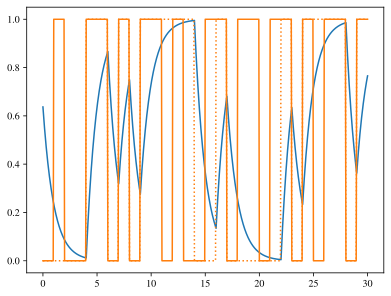

In [ ]:
plt.plot(tmp_t, tmp_x)
plt.plot(tmp_t, tmp_u, ls=':')
plt.plot(tmp_t, tmp_a, c='tab:orange')

In [ ]:
episode_steps_resampled = resample_episode(stitched_episode, step_dt_new, INTERNAL_DT)

In [ ]:
tmp = stitch_internal_traj_NEW([info for _,_,_,_,_,info in episode_steps_resampled], step_dt_new)

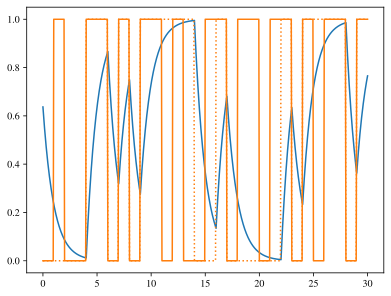

In [ ]:
plt.plot(tmp['t_traj'], tmp['x_traj'])
plt.plot(tmp['t_traj'], tmp['u_traj'], ls=':')
plt.plot(tmp['t_traj'], tmp['a_traj'], c='tab:orange')

In [ ]:
episode_data[0]

[(1,
  1,
  0,
  0.0,
  0,
  {'u': 0,
   'internal_t': array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
          0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
   'internal_x': array([0.63696169, 0.6058967 , 0.57634677, 0.548238  , 0.52150012,
          0.49606626, 0.47187282, 0.44885931, 0.42696819, 0.4061447 ,
          0.38633679, 0.36749492, 0.34957199, 0.33252316, 0.31630581,
          0.3008794 , 0.28620534, 0.27224694, 0.2589693 , 0.24633921,
          0.23432511]),
   'internal_u': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
   'continuous_x_start': 0.6369616873214543,
   'continuous_x_end': 0.2343251095794357,
   'slip_status': 'success',
   'a_last_requested': 0,
   'u_last_effective': 0}),
 (0,
  0,
  1,
  0.0,
  0,
  {'u': 0,
   'internal_t': array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
          0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
   'internal_x': array

In [ ]:
episode_steps_resampled

[(1,
  1,
  np.int64(0),
  0.0,
  0,
  {'internal_t': array([0.  , 0.05, 0.1 , 0.15, 0.2 ]),
   'internal_x': array([0.63696169, 0.6058967 , 0.57634677, 0.548238  , 0.52150012]),
   'internal_u': array([0, 0, 0, 0, 0]),
   'continuous_x_start': np.float64(0.6369616873214543),
   'continuous_x_end': np.float64(0.5215001219425164),
   'slip_status': 'success',
   'a_last_requested': np.int64(0),
   'u_last_effective': np.int64(0),
   'u': np.int64(0)}),
 (np.int64(0),
  0,
  np.int64(0),
  0.0,
  0,
  {'internal_t': array([0.  , 0.05, 0.1 , 0.15, 0.2 ]),
   'internal_x': array([0.52150012, 0.49606626, 0.47187282, 0.44885931, 0.42696819]),
   'internal_u': array([0, 0, 0, 0, 0]),
   'continuous_x_start': np.float64(0.5215001219425164),
   'continuous_x_end': np.float64(0.42696818756825583),
   'slip_status': 'success',
   'a_last_requested': np.int64(0),
   'u_last_effective': np.int64(0),
   'u': np.int64(0)}),
 (np.int64(0),
  0,
  np.int64(0),
  0.0,
  0,
  {'internal_t': array([0.  , 

### One Run - with helper functions

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=0.05),
    max_episode_steps=100,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.05, slip_prob=0.2


In [ ]:
π_b = np.array([[0.1, 0.9], [0.1, 0.9]])
episode_data_raw = generate_dataset(env, π_b, seed=0, num_episodes=100, show_progress=False)
results = run_experiment(episode_data_raw)

In [ ]:
results['orig']['π'], results['shifted']['π']

(array([[0., 1.],
        [1., 0.]]),
 array([[0., 1.],
        [0., 1.]]))

In [ ]:
results['orig']['P'], results['shifted']['P']

(array([[[0.28704784, 0.71295216],
         [0.24752475, 0.75247525]],
 
        [[0.05687204, 0.94312796],
         [0.08178694, 0.91821306]]]),
 array([[[1.        , 0.        ],
         [0.20932642, 0.79067358]],
 
        [[0.77316294, 0.22683706],
         [0.        , 1.        ]]]))

In [ ]:
episode_data_re = [resample_episode(stitch_internal_traj_NEW([xx[-1] for xx in ep], 1.0), 0.25, 0.05) for ep in episode_data_raw]
results_re = run_experiment(episode_data_re)

In [ ]:
results_re['orig']['π'], results_re['shifted']['π']

(array([[0., 1.],
        [1., 0.]]),
 array([[0., 1.],
        [0., 1.]]))

In [ ]:
results_re['orig']['P'], results_re['shifted']['P']

(array([[[0.81579741, 0.18420259],
         [0.81188119, 0.18811881]],
 
        [[0.01411765, 0.98588235],
         [0.02038544, 0.97961456]]]),
 array([[[1.        , 0.        ],
         [0.51432209, 0.48567791]],
 
        [[0.46007605, 0.53992395],
         [0.        , 1.        ]]]))

### Near-Optimal Behavior

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100
BEHAVIOR_POLICY_FUNC = generate_near_optimal_behavior_policy

In [ ]:
resample_dt_list = [4, 2, 1, 0.5, 0.25]

In [ ]:
resample_dt_results = {}
for resample_dt in resample_dt_list:

    # underlying env operates at 1.0 per step
    # so internal_dt must be at most 1.0
    internal_dt = min(1.0, resample_dt)

    print(f'resample_dt={resample_dt}, internal_dt={internal_dt}')

    env = TimeLimit(
        ToyEnvNew(slip_prob=0.1, internal_dt=internal_dt),
        max_episode_steps=MAX_EPISODES_STEPS,
    )

    all_results = []
    for run in tqdm(range(100)):
        π_b = BEHAVIOR_POLICY_FUNC(2, 2, seed=run)
        episode_data_raw = generate_dataset(env, π_b, seed=100+run, num_episodes=NUM_EPISODES, show_progress=False)
        episode_data = [resample_episode(stitch_internal_traj_NEW([xx[-1] for xx in ep], 1.0), resample_dt, internal_dt) for ep in episode_data_raw]
        results = run_experiment_alt(episode_data)
        all_results.append(results)

    resample_dt_results[resample_dt] = all_results

resample_dt=4, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.1


 25%|██▌       | 25/100 [00:22<01:05,  1.15it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 100/100 [01:28<00:00,  1.14it/s]


resample_dt=2, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.1


100%|██████████| 100/100 [01:32<00:00,  1.08it/s]


resample_dt=1, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.1


100%|██████████| 100/100 [01:41<00:00,  1.01s/it]


resample_dt=0.5, internal_dt=0.5
ToyEnvNew initialized. step_dt=1.0, internal_dt=0.5, slip_prob=0.1


100%|██████████| 100/100 [02:10<00:00,  1.31s/it]


resample_dt=0.25, internal_dt=0.25
ToyEnvNew initialized. step_dt=1.0, internal_dt=0.25, slip_prob=0.1


100%|██████████| 100/100 [02:57<00:00,  1.77s/it]


In [ ]:
orig_optimality_rate = []
shifted_optimality_rate = []

for resample_dt in resample_dt_list:
    all_results = resample_dt_results[resample_dt]

    # average P
    avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
    avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)

    # average R
    avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
    avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)

    # average V
    avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
    avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)

    # average Q
    avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
    avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)

    # average π
    avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
    avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)

    print(f'resample_dt={resample_dt}')
    print('orig')
    print(f'avg_P_orig={avg_P_orig}')
    # print(f'avg_π_orig={avg_π_orig}')
    # print(f'optimality rate={avg_π_orig[:,1].mean()}')
    print('shifted')
    print(f'avg_P_shifted={avg_P_shifted}')
    # print(f'avg_π_shifted={avg_π_shifted}')
    # print(f'optimality rate={avg_π_shifted[:,1].mean()}')
    print()

    orig_optimality_rate.append(avg_π_orig[:,1].mean())
    shifted_optimality_rate.append(avg_π_shifted[:,1].mean())

resample_dt=4
orig
avg_P_orig=[[[0.05023325 0.94976675]
  [0.0866276  0.9133724 ]]

 [[0.05023325 0.94976675]
  [0.0866276  0.9133724 ]]]
shifted
avg_P_shifted=[[[0.78667388 0.21332612]
  [0.065937   0.934063  ]]

 [[0.78667388 0.21332612]
  [0.065937   0.934063  ]]]

resample_dt=2
orig
avg_P_orig=[[[0.04410234 0.95589766]
  [0.0466456  0.9533544 ]]

 [[0.04410234 0.95589766]
  [0.0466456  0.9533544 ]]]
shifted
avg_P_shifted=[[[0.84792323 0.15207677]
  [0.02454415 0.97545585]]

 [[0.84792323 0.15207677]
  [0.02454415 0.97545585]]]

resample_dt=1
orig
avg_P_orig=[[[0.14154999 0.85845001]
  [0.02443005 0.97556995]]

 [[0.14154999 0.85845001]
  [0.02443005 0.97556995]]]
shifted
avg_P_shifted=[[[0.90528922 0.09471078]
  [0.00381248 0.99618752]]

 [[0.90528922 0.09471078]
  [0.00381248 0.99618752]]]

resample_dt=0.5
orig
avg_P_orig=[[[0.47023159 0.52976841]
  [0.01409651 0.98590349]]

 [[0.47023159 0.52976841]
  [0.01409651 0.98590349]]]
shifted
avg_P_shifted=[[[0.90528922 0.09471078]
  [0.

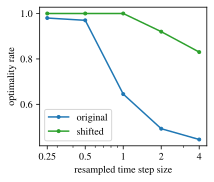

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(3,2.5))
plt.plot(resample_dt_list, orig_optimality_rate, marker='.', c='tab:blue', label='original')
plt.plot(resample_dt_list, shifted_optimality_rate, marker='.', c='tab:green', label='shifted')
plt.xlabel('resampled time step size')
plt.ylabel('optimality rate')
plt.xscale('log')
plt.xticks(resample_dt_list, resample_dt_list)
plt.legend()
plt.savefig('toy_problem_near_deterministic_dt_optimality_rate.pdf', bbox_inches='tight')
plt.show()

### Random Behavior

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100
BEHAVIOR_POLICY_FUNC = generate_random_behavior_policy

In [ ]:
resample_dt_list = [4, 2, 1, 0.5, 0.25]

In [ ]:
resample_dt_results = {}
for resample_dt in resample_dt_list:

    # underlying env operates at 1.0 per step
    # so internal_dt must be at most 1.0
    internal_dt = min(1.0, resample_dt)

    print(f'resample_dt={resample_dt}, internal_dt={internal_dt}')

    env = TimeLimit(
        ToyEnvNew(slip_prob=0.2, internal_dt=internal_dt),
        max_episode_steps=MAX_EPISODES_STEPS,
    )

    all_results = []
    for run in tqdm(range(100)):
        π_b = BEHAVIOR_POLICY_FUNC(2, 2, seed=run)
        episode_data_raw = generate_dataset(env, π_b, seed=100+run, num_episodes=NUM_EPISODES, show_progress=False)
        episode_data = [resample_episode(stitch_internal_traj_NEW([xx[-1] for xx in ep], 1.0), resample_dt, internal_dt) for ep in episode_data_raw]
        results = run_experiment_alt(episode_data)
        all_results.append(results)

    resample_dt_results[resample_dt] = all_results

resample_dt=4, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.2


100%|██████████| 100/100 [01:33<00:00,  1.07it/s]


resample_dt=2, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.2


100%|██████████| 100/100 [01:31<00:00,  1.09it/s]


resample_dt=1, internal_dt=1.0
ToyEnvNew initialized. step_dt=1.0, internal_dt=1.0, slip_prob=0.2


 25%|██▌       | 25/100 [00:25<01:28,  1.19s/it]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 100/100 [01:39<00:00,  1.00it/s]


resample_dt=0.5, internal_dt=0.5
ToyEnvNew initialized. step_dt=1.0, internal_dt=0.5, slip_prob=0.2


100%|██████████| 100/100 [02:08<00:00,  1.28s/it]


resample_dt=0.25, internal_dt=0.25
ToyEnvNew initialized. step_dt=1.0, internal_dt=0.25, slip_prob=0.2


100%|██████████| 100/100 [02:58<00:00,  1.79s/it]


In [ ]:
orig_optimality_rate = []
shifted_optimality_rate = []

for resample_dt in resample_dt_list:
    all_results = resample_dt_results[resample_dt]

    # average P
    avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
    avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)

    # average R
    avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
    avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)

    # average V
    avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
    avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)

    # average Q
    avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
    avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)

    # average π
    avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
    avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)

    print(f'resample_dt={resample_dt}')
    print('orig')
    print(f'avg_π_orig={avg_π_orig}')
    print(f'optimality rate={avg_π_orig[:,1].mean()}')
    print('shifted')
    print(f'avg_π_shifted={avg_π_shifted}')
    print(f'optimality rate={avg_π_shifted[:,1].mean()}')
    print()

    orig_optimality_rate.append(avg_π_orig[:,1].mean())
    shifted_optimality_rate.append(avg_π_shifted[:,1].mean())

resample_dt=4
orig
avg_π_orig=[[0.45 0.55]
 [0.49 0.51]]
optimality rate=0.53
shifted
avg_π_shifted=[[0.   1.  ]
 [0.08 0.92]]
optimality rate=0.96

resample_dt=2
orig
avg_π_orig=[[0.72 0.28]
 [0.72 0.28]]
optimality rate=0.28
shifted
avg_π_shifted=[[0. 1.]
 [0. 1.]]
optimality rate=1.0

resample_dt=1
orig
avg_π_orig=[[0.16 0.84]
 [0.13 0.87]]
optimality rate=0.855
shifted
avg_π_shifted=[[0. 1.]
 [0. 1.]]
optimality rate=1.0

resample_dt=0.5
orig
avg_π_orig=[[0.01 0.99]
 [0.   1.  ]]
optimality rate=0.995
shifted
avg_π_shifted=[[0. 1.]
 [0. 1.]]
optimality rate=1.0

resample_dt=0.25
orig
avg_π_orig=[[0.01 0.99]
 [0.   1.  ]]
optimality rate=0.995
shifted
avg_π_shifted=[[0. 1.]
 [0. 1.]]
optimality rate=1.0



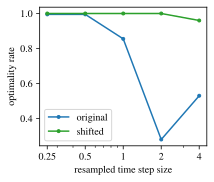

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(3,2.5))
plt.plot(resample_dt_list, orig_optimality_rate, marker='.', c='tab:blue', label='original')
plt.plot(resample_dt_list, shifted_optimality_rate, marker='.', c='tab:green', label='shifted')
plt.xlabel('resampled time step size')
plt.ylabel('optimality rate')
plt.xscale('log')
plt.xticks(resample_dt_list, resample_dt_list)
plt.legend()
plt.savefig('toy_problem_stochastic_dt_optimality_rate.pdf', bbox_inches='tight')
plt.show()

## Lagged Control with Augmented State Space

In [ ]:
def create_augmented_state_mappers(nS_original, nA_original):
    """
    Generates mappings between (s_current, a_previous_requested) tuples
    and unique integer indices for an augmented state space.

    Args:
        nS_original (int): The number of states in the original environment.
        nA_original (int): The number of actions in the original environment.

    Returns:
        tuple:
            - state_to_idx_map (dict): Maps (s, a_prev) tuple to a unique index.
            - idx_to_state_map (dict): Maps a unique index back to (s, a_prev) tuple.
            - num_aug_states (int): The total number of lagged states.
    """
    state_to_idx_map = {}
    idx_to_state_map = {}
    idx = 0

    for s_original in range(nS_original):
        for a_previous_requested in range(nA_original):
            state_tuple = (s_original, a_previous_requested)
            state_to_idx_map[state_tuple] = idx
            idx_to_state_map[idx] = state_tuple
            idx += 1

    num_aug_states = nS_original * nA_original

    print(f"Created {num_aug_states} augmented states.")
    return state_to_idx_map, idx_to_state_map, num_aug_states

def postprocess_state_augmented_episodes(episode_data_raw, state_to_idx_map):
    """
    Given the raw episode data, remap the states to use an augmented state space.

    Args:
        episode_data_raw (list): A list of episodes, where each episode is a list
                                 of tuples (a_curr, s, a, r, s_next, info).
        state_to_idx_map (dict): A dictionary mapping (s, a_prev) tuples to unique
                                 integer indices.

    Returns:
        list: A list of processed episodes, where each step is (aug_s_idx, a, r, aug_s_next_idx).
    """
    aug_episodes = []

    for episode in episode_data_raw:
        aug_episode_steps = []
        for a_curr, s, a, r, s_next, info in episode:
            # Construct the current aug state tuple (s_t, a_{t-1}) -> (s, a_curr)
            current_aug_state = (s, a_curr)

            # Construct the next aug state tuple (s_{t+1}, a_t) -> (s_next, a)
            next_aug_state = (s_next, a)

            # Get the integer index for the current and next aug states
            aug_s_idx = state_to_idx_map[current_aug_state]
            aug_s_next_idx = state_to_idx_map[next_aug_state]

            # Append the transformed step
            aug_episode_steps.append((aug_s_idx, a, r, aug_s_next_idx))
        aug_episodes.append(aug_episode_steps)

    return aug_episodes

### Model-based RL functions

In [ ]:
def calculate_reward_function(episodes):
    R_samples = defaultdict(list)
    for ep in episodes:
        for S, A, R, S_next in ep:
            R_samples[S, A].append(R)

    R = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            R[s,a] = np.mean(R_samples[s,a])

    return R

def calculate_transition_function(episodes):
    P = np.zeros((nS, nA, nS))
    for ep in episodes:
        for S, A, R, S_next in ep:
            P[S, A, S_next] += 1

    for s in range(nS):
        for a in range(nA):
            P[s, a, :] /= np.sum(P[s, a, :])

    return P

def calculate_reward_function_augS(aug_episodes, num_aug_states, num_actions):
    """
    Estimates the reward function for the state-augmented MDP.

    Args:
        aug_episodes (list): A list of episodes in the augmented state space,
                             where each step is (aug_s_idx, a, r, aug_s_next_idx).
        num_aug_states (int): The total number of augmented states.
        num_actions (int): The total number of actions.

    Returns:
        np.ndarray: The estimated reward function R[aug_s, a].
    """
    R_samples = defaultdict(list)
    for ep in aug_episodes:
        for S, A, R, S_next in ep:
            R_samples[(S, A)].append(R)

    R_aug = np.zeros((num_aug_states, num_actions))
    for aug_s in range(num_aug_states):
        for a in range(num_actions):
            R_aug[aug_s, a] = np.mean(R_samples[(aug_s, a)])
    return R_aug

def calculate_transition_function_augS(aug_episodes, num_aug_states, num_actions):
    """
    Estimates the transition function for the state-augmented MDP.

    Args:
        aug_episodes (list): A list of episodes in the augmented state space,
                             where each step is (aug_s_idx, a, r, aug_s_next_idx).
        num_aug_states (int): The total number of augmented states.
        num_actions (int): The total number of actions.

    Returns:
        np.ndarray: The estimated transition function P[aug_s, a, aug_s_next].
    """
    P_counts = np.zeros((num_aug_states, num_actions, num_aug_states))
    for ep in aug_episodes:
        for S, A, R, S_next in ep:
            P_counts[S, A, S_next] += 1

    P_aug = np.zeros((num_aug_states, num_actions, num_aug_states))
    for aug_s in range(num_aug_states):
        for a in range(num_actions):
            P_aug[aug_s, a, :] = P_counts[aug_s, a, :] / np.sum(P_counts[aug_s, a, :])
    return P_aug

def value_iteration_augS(P, R, num_aug_states, num_actions, gamma=0.9, theta=1e-10):
    """
    Performs value iteration for a state-augmented MDP.

    Args:
        P (np.ndarray): The estimated transition function P[aug_s, a, aug_s_next].
        R (np.ndarray): The estimated reward function R[aug_s, a].
        num_aug_states (int): The total number of augmented states.
        num_actions (int): The total number of actions.
        gamma (float): The discount factor.
        theta (float): The convergence threshold.

    Returns:
        tuple:
            - V (np.ndarray): The optimal value function.
            - Q (np.ndarray): The optimal Q-value function.
            - pi (np.ndarray): The optimal policy.
    """
    V = np.zeros(num_aug_states)
    while True:
        Q = np.zeros((num_aug_states, num_actions))
        for aug_s in range(num_aug_states):
            for a in range(num_actions):
                Q[aug_s, a] = R[aug_s, a] + gamma * np.nansum(P[aug_s, a, :] * V)

        V_new = np.nanmax(Q, axis=1)
        delta = np.nanmax(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break

    # Calculate final Q-values
    Q = np.zeros((num_aug_states, num_actions))
    for aug_s in range(num_aug_states):
        for a in range(num_actions):
            Q[aug_s, a] = R[aug_s, a] + gamma * np.nansum(P[aug_s, a, :] * V)

    # Final policy with tie-breaking
    π = (Q == np.nanmax(Q, axis=1, keepdims=True))
    π = π / π.sum(axis=1, keepdims=True)

    return V, Q, π

In [ ]:
def run_experiment_augS(episode_data_raw, state_to_idx_map, num_aug_states, num_actions):
    """
    Runs the experiment for the state-augmented MDP, estimating R, P, V, Q, and pi.

    Args:
        episode_data_raw (list): Raw episode data.
        state_to_idx_map (dict): Mapping from (s, a_prev) to augmented state index.
        num_aug_states (int): Total number of augmented states.
        num_actions (int): Total number of actions.

    Returns:
        dict: Results for 'orig' and 'shifted' contexts.
    """
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data_raw
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data_raw
    ]

    # Calculate reward and transition functions for 'orig' (non-lagged) (uses original nS, nA)
    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function(episodes_orig)
    V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

    # Calculate reward and transition functions for 'shifted' (non-lagged) (uses original nS, nA)
    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function(episodes_shifted)
    V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

    # Calculate reward and transition functions for 'shifted' (lagged) (uses num_aug_states, num_actions)
    episodes_aug = postprocess_state_augmented_episodes(episode_data_raw, state_to_idx_map)
    R_aug = calculate_reward_function_augS(episodes_aug, num_aug_states, num_actions)
    P_aug = calculate_transition_function_augS(episodes_aug, num_aug_states, num_actions)
    V_aug, Q_aug, π_aug = value_iteration_augS(P_aug, R_aug, num_aug_states, num_actions)

    return {
        'orig': {
            'R': R_orig, 'P': P_orig, 'V': V_orig, 'Q': Q_orig, 'π': π_orig,
        },
        'shifted': {
            'R': R_shifted, 'P': P_shifted, 'V': V_shifted, 'Q': Q_shifted, 'π': π_shifted,
        },
        'shifted_aug': {
            'R': R_aug, 'P': P_aug, 'V': V_aug, 'Q': Q_aug, 'π': π_aug,
        }
    }

### One Run

In [ ]:
nS_original = 2
nA_original = 2

# 2. Create the lagged state mappers
state_to_idx_map, idx_to_state_map, num_aug_states = create_augmented_state_mappers(nS_original, nA_original)

# 3. Instantiate the ToyEnvDelayControl environment
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100
env = TimeLimit(
    ToyEnvDelayControl(slip_prob=0.2),
    max_episode_steps=MAX_EPISODES_STEPS,
)

# 4. Define a random behavior policy π_b
π_b = generate_random_behavior_policy(nS_original, nA_original, seed=10)

# 5. Generate raw episode data
print("Generating episode data...")
episode_data_raw = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=42, show_progress=False)
print(f"Generated {len(episode_data_raw)} episodes with {len(episode_data_raw[0])} steps each.")

# 6. Run the experiment
print("Running experiment...")
results_augS = run_experiment_augS(episode_data_raw, state_to_idx_map, num_aug_states, nA_original)
results = run_experiment(episode_data_raw)

# 7. Print the learned optimal policies
print("\nLearned optimal policies:")
print("Original Policy:\n", results['orig']['π'])
print("Shifted Policy:\n", results['shifted']['π'])
print("Original Policy (s,a):\n", results_augS['orig']['π'])
print("Shifted Policy (s,a):\n", results_augS['shifted']['π'])
print("Shifted, state-augmented Policy (aug_s,a):\n", results_augS['shifted_aug']['π'])

Created 4 augmented states.
ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2
ToyEnvDelayControl initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2
Generating episode data...
Generated 100 episodes with 100 steps each.
Running experiment...

Learned optimal policies:
Original Policy:
 [[0. 1.]
 [0. 1.]]
Shifted Policy:
 [[1. 0.]
 [0. 1.]]
Original Policy (s,a):
 [[0. 1.]
 [0. 1.]]
Shifted Policy (s,a):
 [[1. 0.]
 [0. 1.]]
Shifted, state-augmented Policy (aug_s,a):
 [[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


### Learning

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100

In [ ]:
state_to_idx_map, idx_to_state_map, num_aug_states = create_augmented_state_mappers(nS_original, nA_original)

Created 4 augmented states.


In [ ]:
env = TimeLimit(
    ToyEnvDelayControl(slip_prob=0.2),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2
ToyEnvDelayControl initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2


In [ ]:
all_results = []
for run in tqdm(range(100)):
    π_b = generate_random_behavior_policy(2, 2, seed=run)
    episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=100+run, show_progress=False)
    results = run_experiment_augS(episode_data, state_to_idx_map, num_aug_states, nA_original)
    all_results.append(results)

 72%|███████▏  | 72/100 [01:09<00:24,  1.15it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipython-input-1100664054.py:71: RuntimeWarning: invalid value encountered in divide
  P_aug[aug_s, a, :] = P_counts[aug_s, a, :] / np.sum(P_counts[aug_s, a, :])
100%|██████████| 100/100 [01:30<00:00,  1.11it/s]


In [ ]:
# average P
avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)
avg_P_shifted_aug = np.nanmean([results['shifted_aug']['P'] for results in all_results], axis=0)

In [ ]:
avg_P_orig, avg_P_shifted, avg_P_shifted_aug

(array([[[1.        , 0.        ],
         [0.20012562, 0.79987438]],
 
        [[0.80043772, 0.19956228],
         [0.        , 1.        ]]]),
 array([[[0.62201525, 0.37798475],
         [0.61925525, 0.38074475]],
 
        [[0.37652025, 0.62347975],
         [0.37301004, 0.62698996]]]),
 array([[[1.        , 0.        , 0.        , 0.        ],
         [0.        , 1.        , 0.        , 0.        ]],
 
        [[0.20030186, 0.        , 0.79969814, 0.        ],
         [0.        , 0.19306432, 0.        , 0.80693568]],
 
        [[0.80392091, 0.        , 0.19607909, 0.        ],
         [0.        , 0.79904667, 0.        , 0.20095333]],
 
        [[0.        , 0.        , 1.        , 0.        ],
         [0.        , 0.        , 0.        , 1.        ]]]))

In [ ]:
# average R
avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)
avg_R_aug = np.nanmean([results['shifted_aug']['R'] for results in all_results], axis=0)

In [ ]:
avg_R_orig, avg_R_shifted, avg_R_aug

(array([[0.        , 0.79987438],
        [0.19956228, 1.        ]]),
 array([[0.37798475, 0.38074475],
        [0.62347975, 0.62698996]]),
 array([[0.        , 0.        ],
        [0.79969814, 0.80693568],
        [0.19607909, 0.20095333],
        [1.        , 1.        ]]))

In [ ]:
# average V
avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)
avg_V_aug = np.nanmean([results['shifted_aug']['V'] for results in all_results], axis=0)

# average Q
avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)
avg_Q_aug = np.nanmean([results['shifted_aug']['Q'] for results in all_results], axis=0)

In [ ]:
# average π
avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)
avg_π_aug = np.nanmean([results['shifted_aug']['π'] for results in all_results], axis=0)

In [ ]:
avg_π_orig, avg_π_shifted, avg_π_aug

(array([[0., 1.],
        [0., 1.]]),
 array([[0.48, 0.52],
        [0.47, 0.53]]),
 array([[0.  , 1.  ],
        [0.01, 0.99],
        [0.  , 1.  ],
        [0.  , 1.  ]]))

### Mixing unlagged vs lagged data

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 200

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.1),
    max_episode_steps=MAX_EPISODES_STEPS,
)
env_lagged = TimeLimit(
    ToyEnvDelayControl(slip_prob=0.1),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1
ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1
ToyEnvDelayControl initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1


In [ ]:
lag_fraction_list = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

In [ ]:
# lag_fraction_list = [0.0, 0.25, 0.5, 0.75, 1.0]

In [ ]:
ALL_all_results = {}
for fraction in lag_fraction_list:
    print(f'fraction={fraction}')

    all_results = []
    for run in tqdm(range(100)):
        π_b = generate_near_optimal_behavior_policy(2, 2, seed=run)

        episode_data = (
            generate_dataset(env_lagged, π_b, num_episodes=int(NUM_EPISODES * fraction), seed=100+run, show_progress=False)
            + generate_dataset(env, π_b, num_episodes=NUM_EPISODES - int(NUM_EPISODES * fraction), seed=200+run, show_progress=False)
        )
        results = run_experiment_augS(episode_data, state_to_idx_map, num_aug_states, nA_original)
        all_results.append(results)
    ALL_all_results[fraction] = all_results

fraction=0.0


  0%|          | 0/100 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipython-input-3509282544.py:71: RuntimeWarning: invalid value encountered in divide
  P_aug[aug_s, a, :] = P_counts[aug_s, a, :] / np.sum(P_counts[aug_s, a, :])
  3%|▎         | 3/100 [00:04<02:16,  1.41s/it]/tmp/ipython-input-3509282544.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
 25%|██▌       | 25/100 [00:37<02:06,  1.69s/it]/tmp/ipython-input-3509282544.py:99: RuntimeWarning: All-NaN slice encountered
  V_new = np.nanmax(Q, axis=1)
/tmp/ipython-input-3509282544.py:112: RuntimeWarning: All-NaN slice encountered
  π = (Q == np.nanmax(Q, axis=1, keepdims=True))
/tmp/ipytho

fraction=0.1


100%|██████████| 100/100 [02:27<00:00,  1.47s/it]


fraction=0.2


...

100%|██████████| 100/100 [02:30<00:00,  1.50s/it]


fraction=0.9


100%|██████████| 100/100 [02:29<00:00,  1.50s/it]


fraction=1.0


100%|██████████| 100/100 [02:29<00:00,  1.50s/it]


In [ ]:
orig_optimality_rate = []
shifted_optimality_rate = []
shifted_aug_optimality_rate = []

for lag_fraction in lag_fraction_list:
    all_results = ALL_all_results[lag_fraction]

    avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
    avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)
    avg_π_shifted_aug = np.nanmean([results['shifted_aug']['π'] for results in all_results], axis=0)

    orig_optimality_rate.append(avg_π_orig[:,1].mean())
    shifted_optimality_rate.append(avg_π_shifted[:,1].mean())
    shifted_aug_optimality_rate.append(avg_π_shifted_aug[:,1].mean())

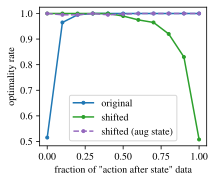

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(3,2.5))
plt.plot(lag_fraction_list, orig_optimality_rate, marker='.', c='tab:blue', label='original')
plt.plot(lag_fraction_list, shifted_optimality_rate, marker='.', c='tab:green', label='shifted')
plt.plot(lag_fraction_list, shifted_aug_optimality_rate, marker='.', ls='--', c='tab:purple', label='shifted (aug state)')
plt.xlabel('fraction of "action after state" data')
plt.ylabel('optimality rate')
# plt.xticks(lag_fraction_list, lag_fraction_list)
plt.legend()
plt.savefig('toy_problem_lag_fraction_optimality_rate.pdf', bbox_inches='tight')
plt.show()

## Download figures

In [ ]:
!zip -r fig.zip *.pdf

  adding: toy_problem_near_deterministic_dt_optimality_rate.pdf (deflated 28%)
  adding: toy_problem_NEW_labeled.pdf (deflated 34%)
  adding: toy_problem_NEW.pdf (deflated 33%)
  adding: toy_problem_stochastic_dt_optimality_rate.pdf (deflated 29%)
